In [1]:
# Customer Churn - Exploratory Data Analysis

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Find project folder and dataset
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_PATH = PROJECT_DIR / "data" / "processed" / "telco_cleaned.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (7043, 21)

First 5 Rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:

# Missing Values Analysis

missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Column": missing_values.index,
    "Missing_Values": missing_values.values
})

missing_report = missing_report[
    missing_report["Missing_Values"] > 0
]

if missing_report.empty:
    print("No missing values found in the dataset.")
else:
    display(missing_report)


No missing values found in the dataset.


Churn Column Values:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


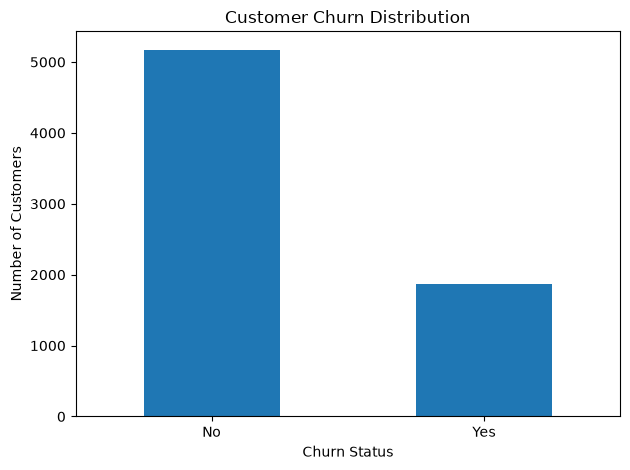

In [3]:

# Customer Churn Distribution

print("Churn Column Values:")
print(df["Churn"].value_counts())

# Display churn chart
df["Churn"].value_counts().plot(
    kind="bar",
    title="Customer Churn Distribution"
)

plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [4]:

# Customer Churn Percentage Analysis

churn_count = df["Churn"].value_counts()
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

churn_summary = pd.DataFrame({
    "Customer_Count": churn_count,
    "Percentage": churn_percentage.round(2)
})

display(churn_summary)


,Customer_Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


Churn Rate by Contract (%):


Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

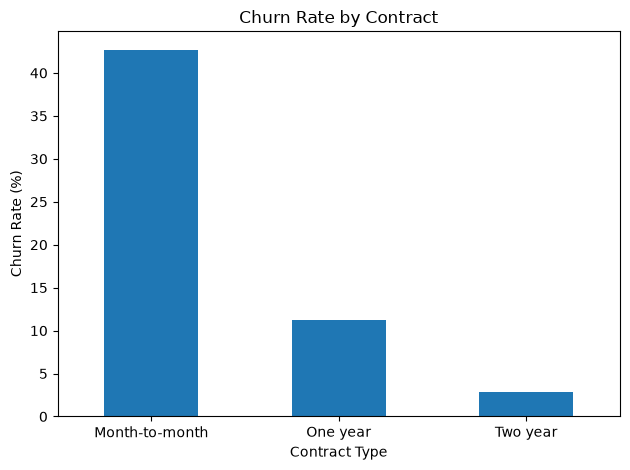

In [5]:

# Customer Churn Rate by Contract

contract_churn = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print("Churn Rate by Contract (%):")
display(contract_churn.round(2))

contract_churn.plot(kind="bar", title="Churn Rate by Contract")

plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Average Monthly Charges by Churn Status:


Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

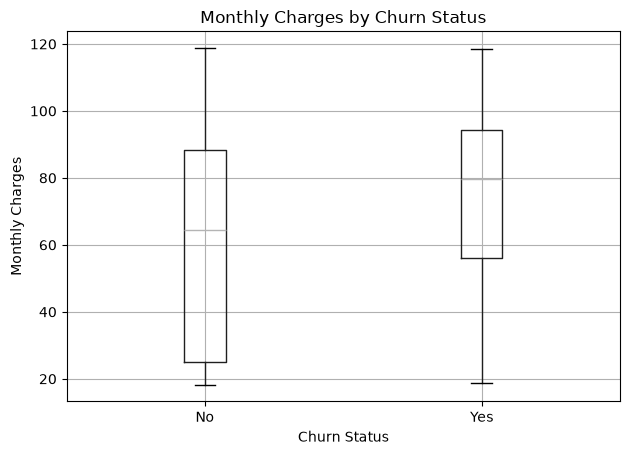

In [6]:

# Monthly Charges by Churn Status

print("Average Monthly Charges by Churn Status:")
display(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

df.boxplot(column="MonthlyCharges", by="Churn")

plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()


Average Tenure by Churn Status:


Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

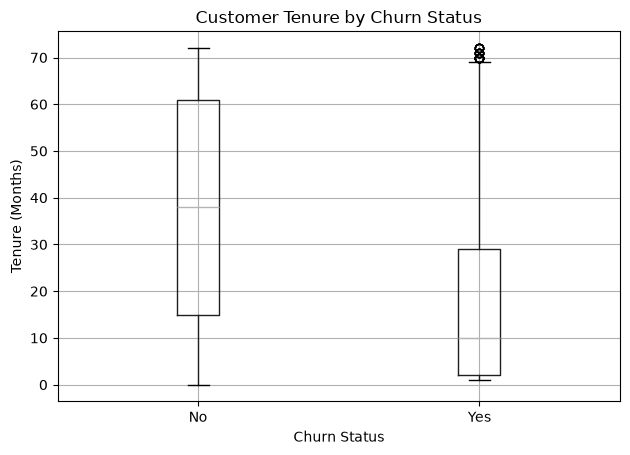

In [7]:

# Customer Tenure by Churn Status

print("Average Tenure by Churn Status:")
display(df.groupby("Churn")["tenure"].mean().round(2))

df.boxplot(column="tenure", by="Churn")

plt.title("Customer Tenure by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()


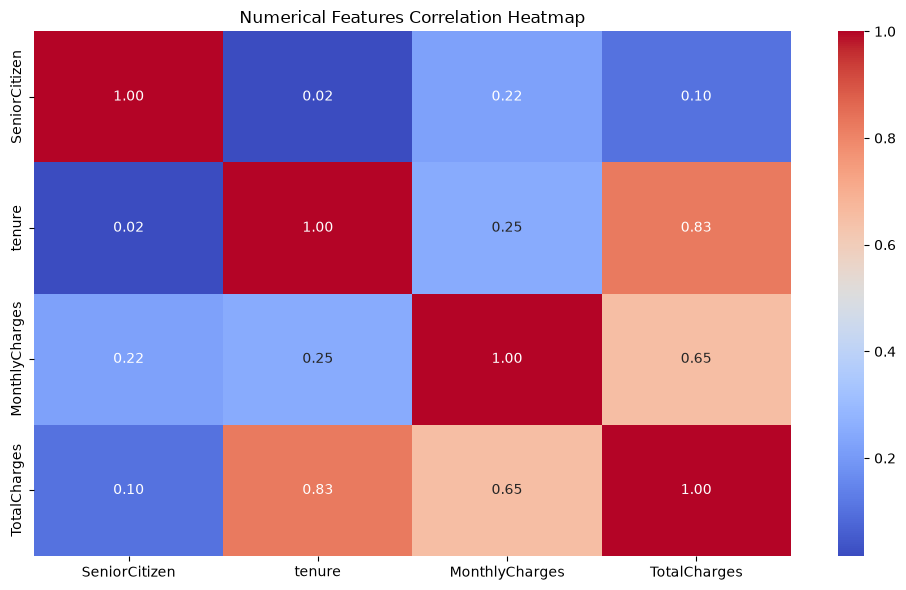

In [8]:

# Numerical Features Correlation Heatmap

import seaborn as sns

numerical_df = df.select_dtypes(include="number")

correlation = numerical_df.corr()

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Features Correlation Heatmap")
plt.tight_layout()
plt.show()


In [9]:

# Customer Churn Model Comparison

from pathlib import Path

PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

MODEL_RESULTS_PATH = (
    PROJECT_DIR / "data" / "processed" / "model_comparison.csv"
)

model_results = pd.read_csv(MODEL_RESULTS_PATH)

print("Model Comparison Results:")
display(model_results)

print("Available Columns:")
print(model_results.columns.tolist())


Model Comparison Results:


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.797729,0.649832,0.516043,0.575261,0.842959
1,Random Forest,0.770050,0.557078,0.652406,0.600985,0.824459


Available Columns:
['Model', 'Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC']


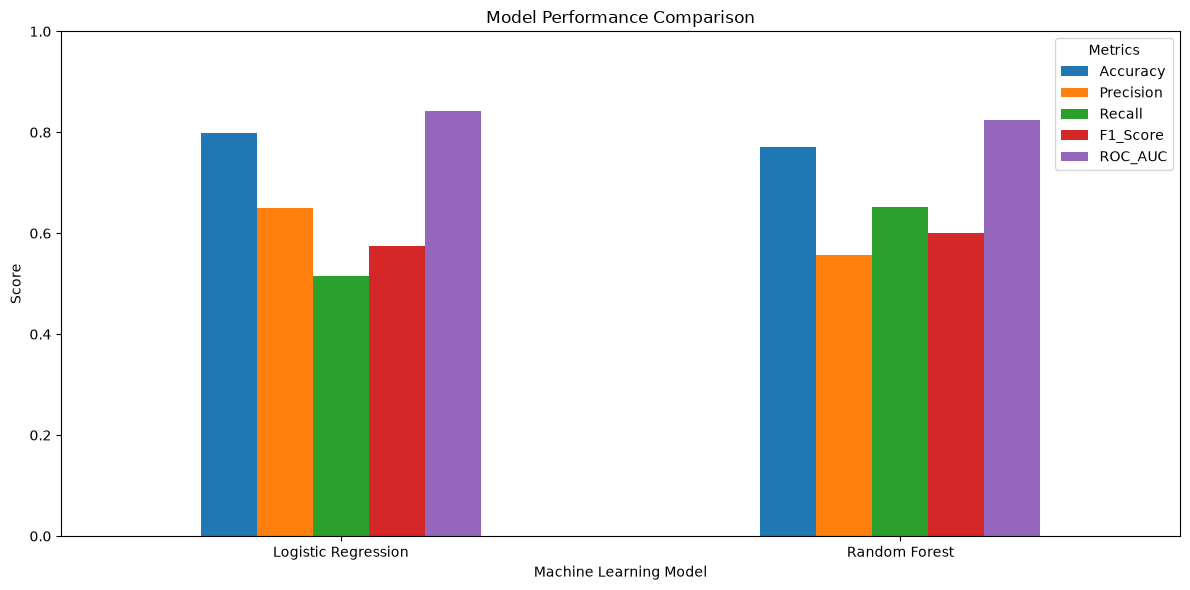

In [10]:

# Customer Churn Model Comparison Chart

metrics = ["Accuracy", "Precision", "Recall", "F1_Score", "ROC_AUC"]

model_results.plot(
    x="Model",
    y=metrics,
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()


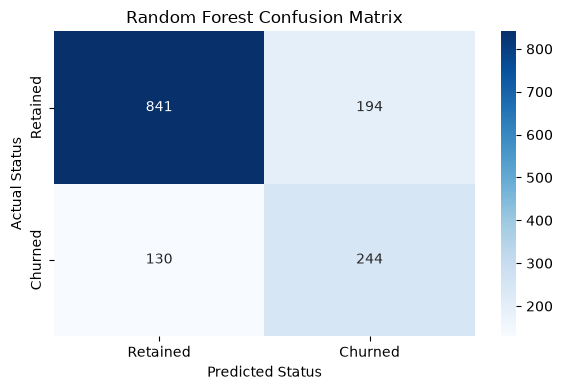

In [11]:

# Random Forest Confusion Matrix Heatmap

from sklearn.metrics import confusion_matrix
import seaborn as sns

y_test = pd.read_csv(
    PROJECT_DIR / "data" / "processed" / "y_test.csv"
).squeeze()

X_test = pd.read_csv(
    PROJECT_DIR / "data" / "processed" / "X_test.csv"
)

import joblib

model = joblib.load(
    PROJECT_DIR / "models" / "best_churn_model.joblib"
)

y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Retained", "Churned"],
    yticklabels=["Retained", "Churned"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.tight_layout()
plt.show()


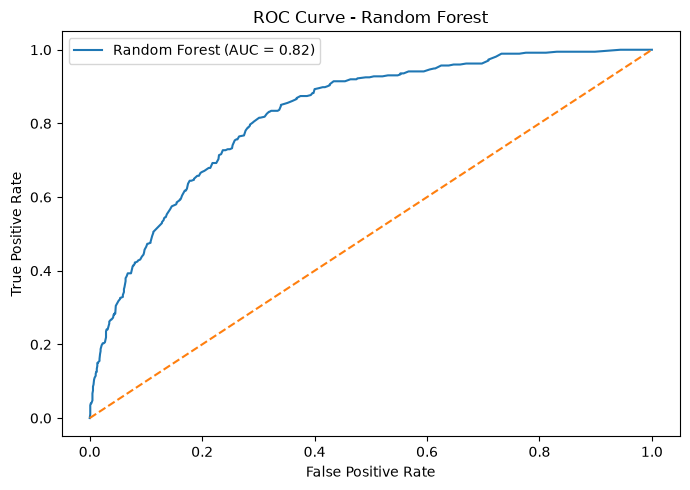

ROC-AUC Score: 0.824


In [12]:

# Random Forest ROC Curve

from sklearn.metrics import roc_curve, roc_auc_score

y_probability = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_probability)

roc_score = roc_auc_score(y_test, y_probability)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_score:.2f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve - Random Forest")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

print("ROC-AUC Score:", round(roc_score, 3))


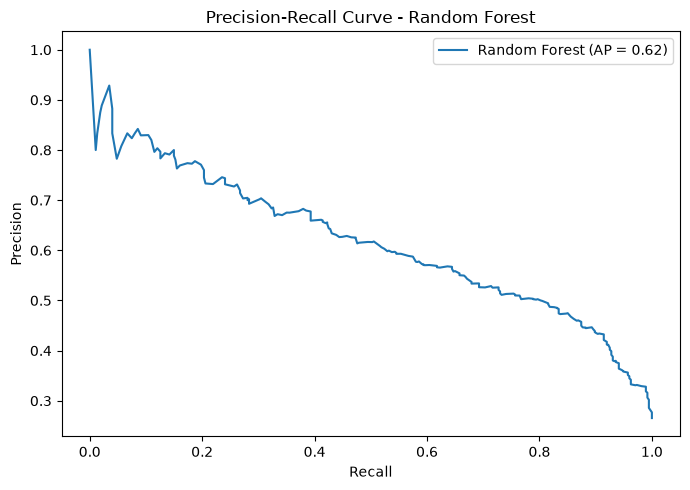

Average Precision Score: 0.616


In [13]:

# Random Forest Precision-Recall Curve

from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, thresholds = precision_recall_curve(
    y_test, y_probability
)

pr_score = average_precision_score(y_test, y_probability)

plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    label=f"Random Forest (AP = {pr_score:.2f})"
)

plt.title("Precision-Recall Curve - Random Forest")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.tight_layout()
plt.show()

print("Average Precision Score:", round(pr_score, 3))


,Feature,Importance
3,TotalCharges,0.129758
1,tenure,0.128655
4,AverageMonthlySpend,0.115132
2,MonthlyCharges,0.111844
27,Contract_Two year,0.049373
12,InternetService_Fiber optic,0.040937
30,PaymentMethod_Electronic check,0.035229
5,ServiceCount,0.031546
34,TenureGroup_New Customer,0.028121
26,Contract_One year,0.023410


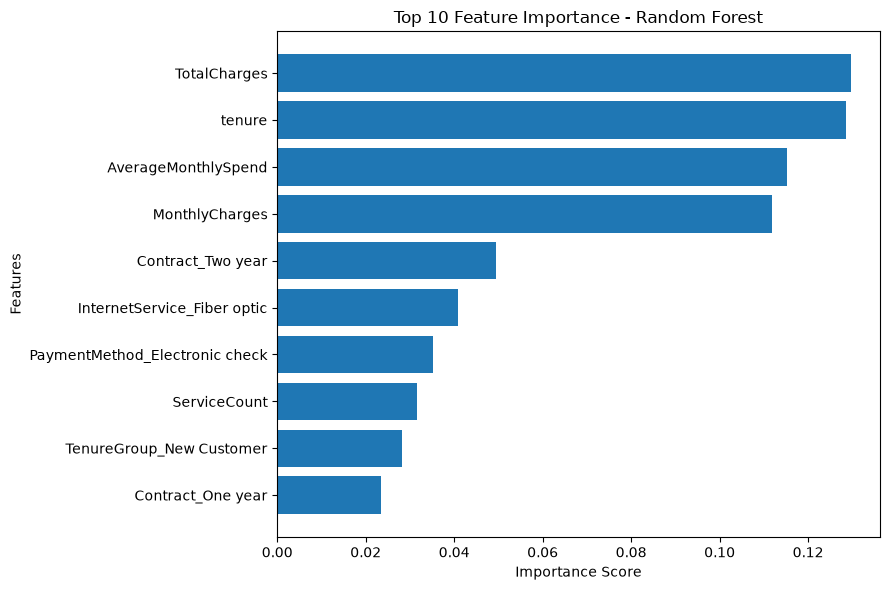

In [14]:

# Customer Churn Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=True
)

display(importance_df.sort_values(
    by="Importance",
    ascending=False
).head(10))

plt.figure(figsize=(9, 6))

plt.barh(
    importance_df["Feature"].tail(10),
    importance_df["Importance"].tail(10)
)

plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


In [15]:

# Customer Segmentation - 2D Scatter Plot

SEGMENT_PATH = (
    PROJECT_DIR / "data" / "processed" / "customer_segments.csv"
)

segments_df = pd.read_csv(SEGMENT_PATH)

print("Customer Segment Columns:")
print(segments_df.columns.tolist())

display(segments_df.head())


Customer Segment Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'CustomerSegment']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerSegment
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,2
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,2
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,2


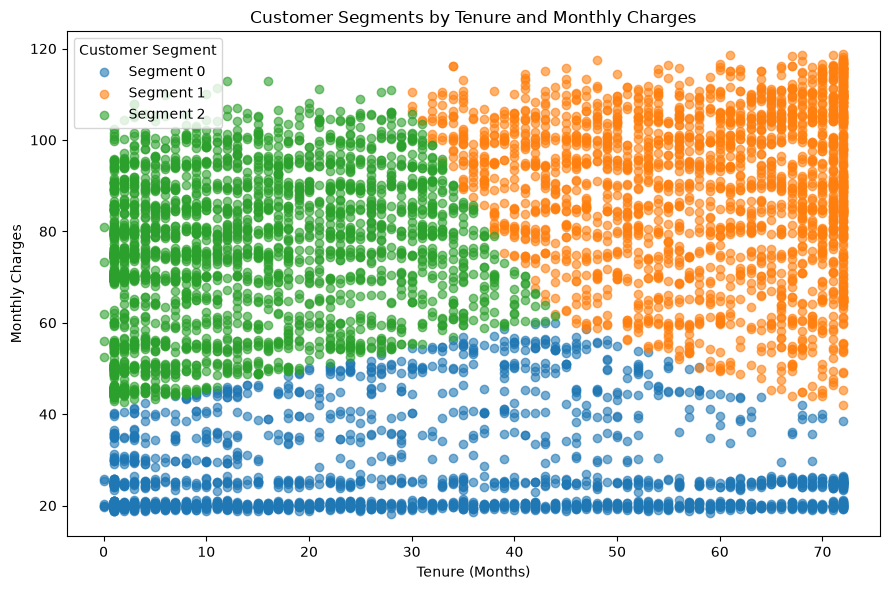

In [16]:

# Customer Segmentation - 2D Scatter Plot

plt.figure(figsize=(9, 6))

for segment in sorted(segments_df["CustomerSegment"].unique()):
    segment_data = segments_df[
        segments_df["CustomerSegment"] == segment
    ]

    plt.scatter(
        segment_data["tenure"],
        segment_data["MonthlyCharges"],
        label=f"Segment {segment}",
        alpha=0.6
    )

plt.title("Customer Segments by Tenure and Monthly Charges")
plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges")
plt.legend(title="Customer Segment")
plt.tight_layout()
plt.show()


In [17]:

# Customer Churn Risk Category Check

print("Available Columns:")
print(df.columns.tolist())

print("\nCustomer Segment Data Columns:")
print(segments_df.columns.tolist())


Available Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Customer Segment Data Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'CustomerSegment']


In [18]:

# Customer Churn Risk Category

risk_data = X_test.copy()

risk_data["Actual_Churn"] = y_test.values
risk_data["Churn_Probability"] = model.predict_proba(X_test)[:, 1]

risk_data["RiskCategory"] = pd.cut(
    risk_data["Churn_Probability"],
    bins=[-0.01, 0.30, 0.60, 1.00],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

print("Customers by Risk Category:")
display(
    risk_data["RiskCategory"]
    .value_counts()
    .rename_axis("Risk Category")
    .reset_index(name="Customer Count")
)


Customers by Risk Category:


,Risk Category,Customer Count
0,Low Risk,739
1,Medium Risk,338
2,High Risk,332


Revenue Exposure by Risk Category:


,RiskCategory,MonthlyRevenue
0,Low Risk,40317.35
1,Medium Risk,24783.60
2,High Risk,25200.25


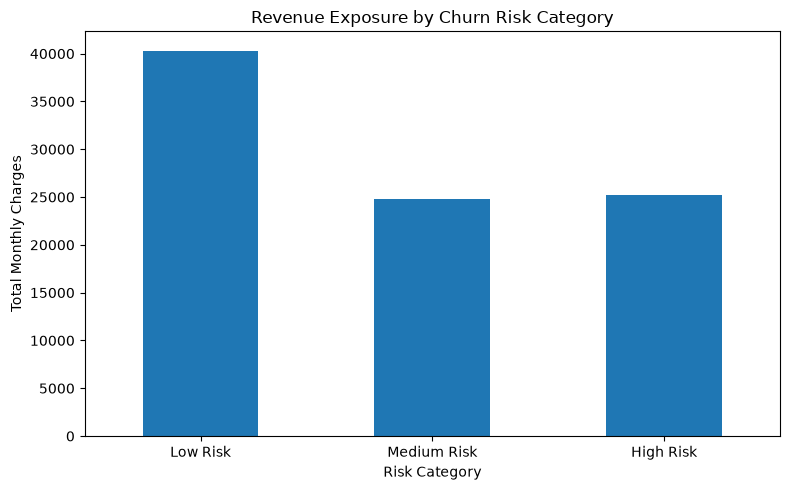

In [19]:

# Revenue Exposure by Risk Category

risk_data["MonthlyRevenue"] = X_test["MonthlyCharges"].values

revenue_exposure = (
    risk_data.groupby("RiskCategory", observed=False)["MonthlyRevenue"]
    .sum()
    .reset_index()
)

print("Revenue Exposure by Risk Category:")
display(revenue_exposure.round(2))

revenue_exposure.plot(
    x="RiskCategory",
    y="MonthlyRevenue",
    kind="bar",
    legend=False,
    figsize=(8, 5)
)

plt.title("Revenue Exposure by Churn Risk Category")
plt.xlabel("Risk Category")
plt.ylabel("Total Monthly Charges")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


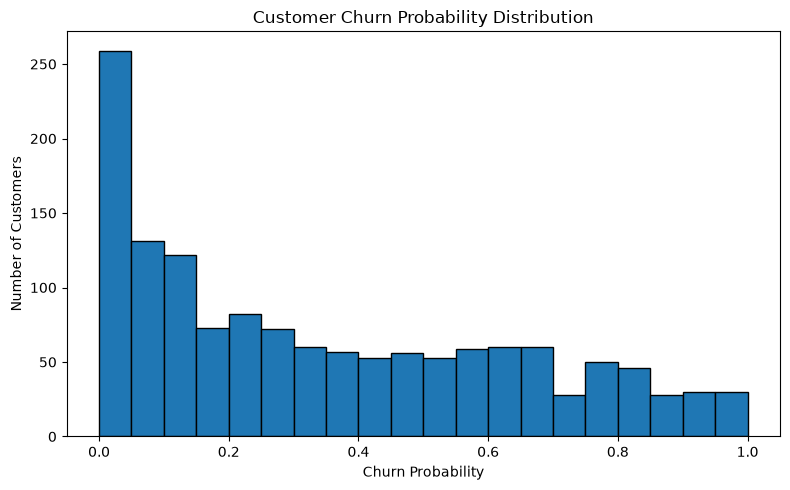

Average Churn Probability: 0.346


In [20]:

# Customer Churn Probability Distribution

plt.figure(figsize=(8, 5))

plt.hist(
    risk_data["Churn_Probability"],
    bins=20,
    edgecolor="black"
)

plt.title("Customer Churn Probability Distribution")
plt.xlabel("Churn Probability")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

print(
    "Average Churn Probability:",
    round(risk_data["Churn_Probability"].mean(), 3)
)
